In [1]:
# ============================================================
# CÉLULA 0 — ESCOLHA DOS PARÂMETROS (OBRIGATÓRIO)
# Confira/altere os valores e clique em "Confirmar parâmetros".
# ============================================================

import ipywidgets as widgets
from IPython.display import display, clear_output

_penalty = widgets.Dropdown(
    options=[('L2 (padrão atual)', 'l2'), ('L1', 'l1'), ('Sem regularização', 'none')],
    value='l2', description='Penalty:', style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)
_max_iter = widgets.BoundedIntText(value=2000, min=1, max=100000, step=100,
    description='Max iter:', style={'description_width': 'initial'})
_random_state = widgets.IntText(value=42, description='Random state:',
    style={'description_width': 'initial'})
_test_size = widgets.Dropdown(
    options=[('10% teste / 90% treino', 0.10), ('20% teste / 80% treino (atual)', 0.20),
             ('25% teste / 75% treino', 0.25), ('30% teste / 70% treino', 0.30),
             ('40% teste / 60% treino', 0.40)],
    value=0.20, description='Divisão treino/teste:', style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)
_confirmar = widgets.Button(description='Confirmar parâmetros', button_style='success', icon='check')
_status = widgets.Output()
_PARAMETROS_CONFIRMADOS = False

_painel = widgets.VBox([
    widgets.HTML('<h3>Configuração da regressão logística — PENSE2024</h3>'),
    widgets.HTML('<p>Os valores atuais já estão selecionados. Confirme-os ou escolha outros antes do treinamento.</p>'),
    _penalty, _max_iter, _random_state, _test_size, _confirmar, _status
], layout=widgets.Layout(border='1px solid #cccccc', padding='12px', width='500px'))

def _confirmar_parametros(_):
    global PENALTY, MAX_ITER, RANDOM_STATE, TEST_SIZE, SOLVER, _PARAMETROS_CONFIRMADOS
    with _status:
        clear_output(wait=True)
        PENALTY = None if _penalty.value == 'none' else _penalty.value
        MAX_ITER = int(_max_iter.value)
        RANDOM_STATE = int(_random_state.value)
        TEST_SIZE = float(_test_size.value)
        SOLVER = 'liblinear' if PENALTY == 'l1' else 'lbfgs'
        _PARAMETROS_CONFIRMADOS = True
        print('Parâmetros confirmados:')
        print(f'  penalty={PENALTY!r}')
        print(f'  max_iter={MAX_ITER}')
        print(f'  random_state={RANDOM_STATE}')
        print(f'  treino/teste={1-TEST_SIZE:.0%}/{TEST_SIZE:.0%}')
        print(f'  solver={SOLVER!r}')
        print('Agora execute a célula de treinamento (Célula 1).')

_confirmar.on_click(_confirmar_parametros)
display(_painel)


DESFECHO: 0 = Não (código original 1); 1 = Sim (código original 3)

Distribuição do desfecho na base utilizável:


,Quantidade,Percentual
0,,
Não (0),78786,67.139339
Sim (1),38561,32.860661


Registros utilizáveis: 117,347
Preditores categóricos utilizados: 38

MÉTRICAS DO TREINO


,Treino (80%)
Acurácia,0.7834
Precisão (Sim),0.7123
Sensibilidade / Recall (Sim),0.5718
Especificidade (Não),0.8870
Valor preditivo negativo,0.8089
F1-score (Sim),0.6343
AUC-ROC,0.8307
Average Precision,0.7158
Brier score (menor é melhor),0.1516



Relatório de classificação — treino:
              precision    recall  f1-score   support

     Não (0)       0.81      0.89      0.85     63028
     Sim (1)       0.71      0.57      0.63     30849

    accuracy                           0.78     93877
   macro avg       0.76      0.73      0.74     93877
weighted avg       0.78      0.78      0.78     93877



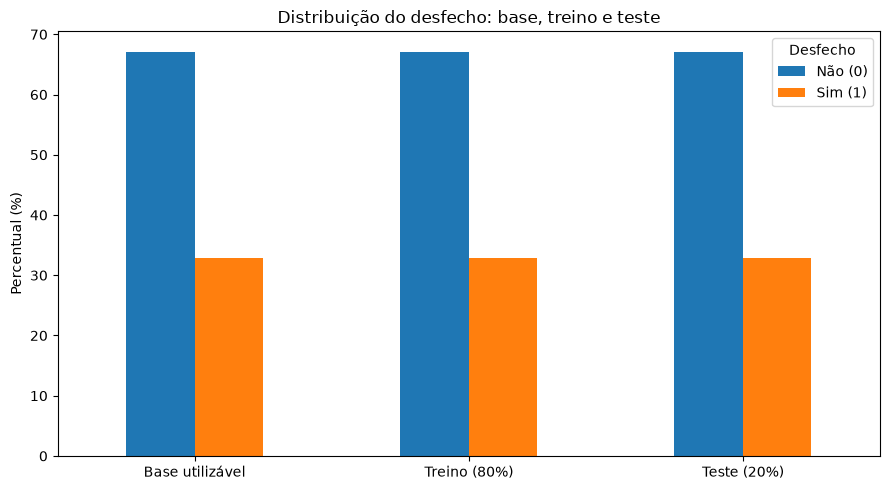

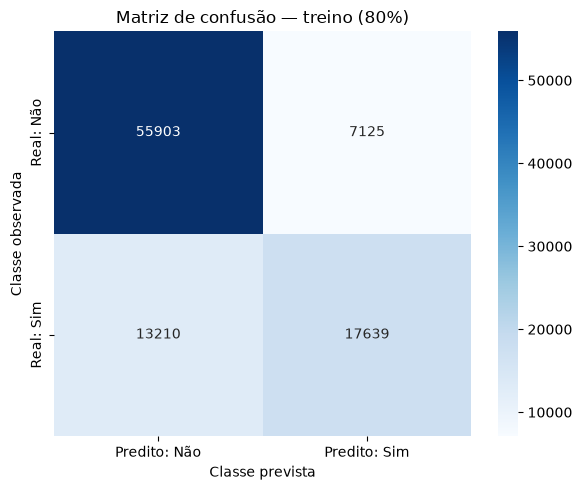

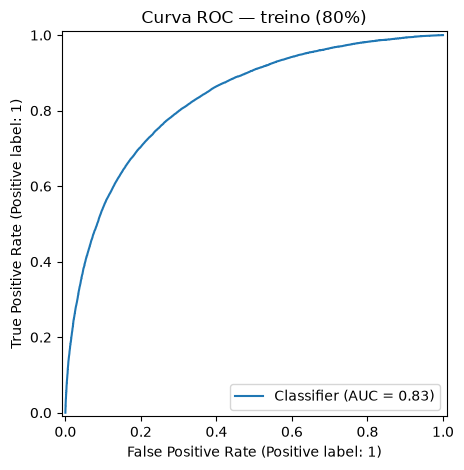

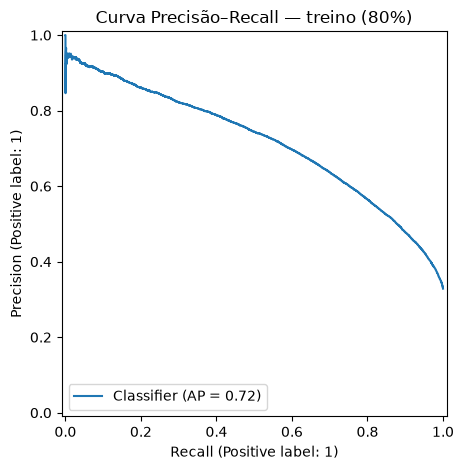

Average Precision no treino: 0.7158


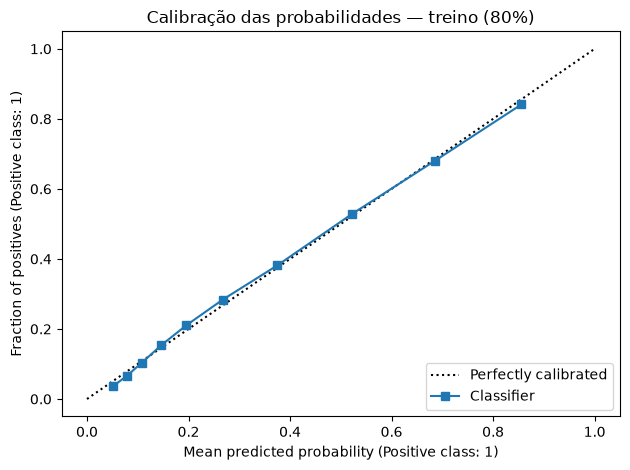

Brier score no treino (menor é melhor): 0.1516

30 categorias com maiores coeficientes absolutos:


,Categoria/preditor,Coeficiente_log_odds,Odds_ratio
62,"categoricas__B12008 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que a vida não vale a pena ser vivida?_3",0.9996,2.7171
53,"categoricas__B12005 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu triste?_3",0.6107,1.8417
61,"categoricas__B12008 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que a vida não vale a pena ser vivida?_2",0.5411,1.7179
1,categoricas__B01001A - Qual é o seu sexo?_2,0.4758,1.6092
70,"categoricas__B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?_3",0.4609,1.5855
20,categoricas__B05002A - Alguma vez na vida você tomou um copo ou uma dose de bebida alcoólica?_1,-0.4442,0.6414
56,"categoricas__B12006 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que ninguém se preocupa com você?_3",0.4407,1.5538
71,"categoricas__B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?_1",-0.4364,0.6464
60,"categoricas__B12008 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que a vida não vale a pena ser vivida?_1",-0.4246,0.6541
66,"categoricas__B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?_3",0.4090,1.5053


/var/folders/6q/rl1jn5t52qg9qxc6f3l113480000gn/T/ipykernel_13616/2039549709.py:231: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


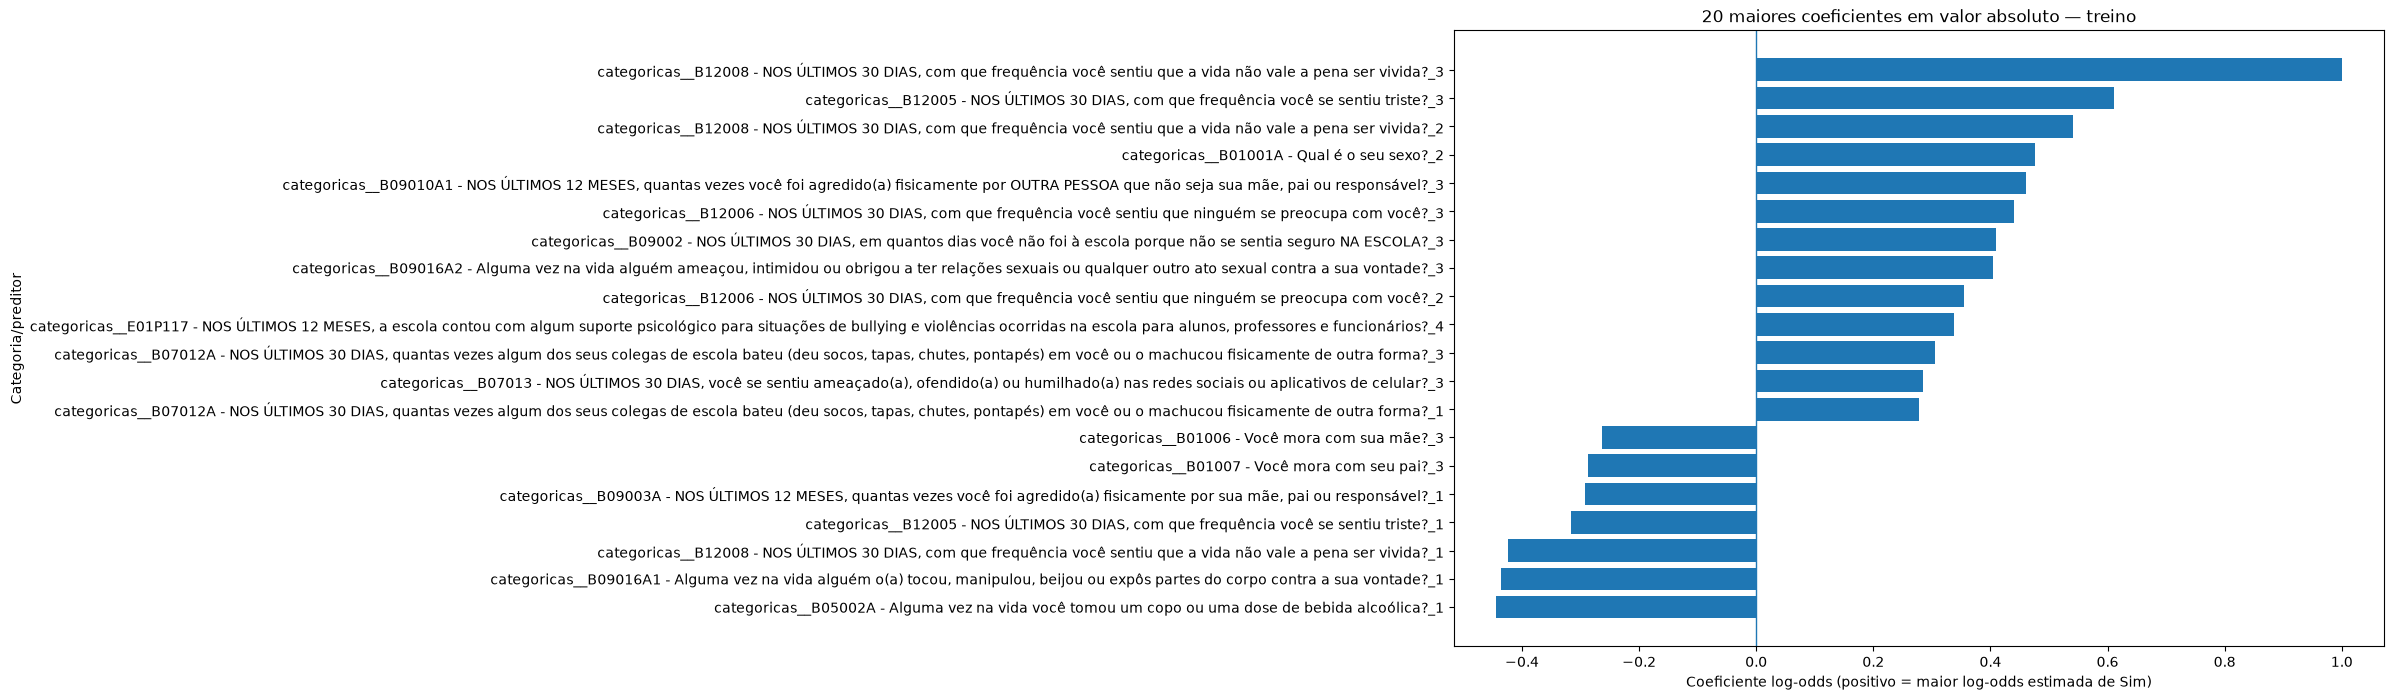


Nota: os gráficos e métricas do treino descrevem o ajuste aos dados usados para estimar o modelo e tendem a ser otimistas. A avaliação final deve ser feita na CÉLULA 2, usando os 20% reservados. Coeficientes/odds ratios são associações ajustadas, não demonstram causalidade e não incluem intervalos de confiança nesta análise.


In [3]:
# ============================================================
# CÉLULA 1 — TREINAMENTO E DIAGNÓSTICO DA REGRESSÃO LOGÍSTICA
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    RocCurveDisplay, PrecisionRecallDisplay, average_precision_score,
    brier_score_loss
)
from sklearn.calibration import CalibrationDisplay

warnings.filterwarnings("ignore", category=FutureWarning)


# ============================================================
# PARÂMETROS definidos na Célula 0 pela tabela interativa
# ============================================================
if not globals().get("_PARAMETROS_CONFIRMADOS", False):
    raise RuntimeError(
        "Antes de treinar, execute a Célula 0 e clique em 'Confirmar parâmetros'."
    )

# Caminho da base de entrada (.feather)
ARQUIVO = "/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/02_Tratamento_dados_database_PENSE_2024/02_Scripts_tratamento_dados_PENSE_2024/07_PENSE2024_IDADE_13_A_17_CATEGORY.feather"

# Desfecho: códigos originais esperados 1 = Não e 3 = Sim
TARGET = "B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você sentiu vontade de se machucar de propósito?"

if not os.path.exists(ARQUIVO):
    raise FileNotFoundError(
        f"Arquivo não encontrado: {ARQUIVO}\n"
        "Atualize a variável ARQUIVO para o caminho correto no seu computador."
    )

df = pd.read_feather(ARQUIVO)
if TARGET not in df.columns:
    raise ValueError(
        f"TARGET não encontrado: {TARGET}\n"
        "Confira o nome exato da coluna no arquivo."
    )

# Conforme solicitado, assumir todas as colunas como categóricas.
dados = df.copy()
for coluna in dados.columns:
    dados[coluna] = dados[coluna].astype("category")

# Remover linhas sem desfecho observado.
dados = dados.loc[dados[TARGET].notna()].copy()

# Recodificação explícita do desfecho: 1 = Não -> 0; 3 = Sim -> 1.
codigo_target = pd.to_numeric(
    dados[TARGET].astype("string").str.extract(r"(\d+)")[0],
    errors="coerce"
)
validos = codigo_target.isin([1, 3])
dados = dados.loc[validos].copy()
codigo_target = codigo_target.loc[validos]
y = codigo_target.map({1: 0, 3: 1}).astype("int64")
X = dados.drop(columns=[TARGET]).astype("object")

# Remover preditores sem valores ou constantes.
colunas_validas = [
    c for c in X.columns
    if X[c].notna().any() and X[c].nunique(dropna=True) > 1
]
X = X[colunas_validas]

if X.shape[1] == 0:
    raise ValueError("Não restaram variáveis preditoras válidas.")
if y.nunique() != 2:
    raise ValueError(
        "Após a recodificação, não há as duas classes esperadas. "
        "Confira os rótulos/códigos da variável TARGET."
    )

print("DESFECHO: 0 = Não (código original 1); 1 = Sim (código original 3)")
print("\nDistribuição do desfecho na base utilizável:")
display(
    y.value_counts().reindex([0, 1], fill_value=0)
    .rename(index={0: "Não (0)", 1: "Sim (1)"})
    .to_frame("Quantidade")
    .assign(Percentual=lambda t: 100 * t["Quantidade"] / len(y))
)
print(f"Registros utilizáveis: {len(y):,}")
print(f"Preditores categóricos utilizados: {X.shape[1]:,}")

# Separar 80% treino / 20% teste antes do pré-processamento para evitar vazamento.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

# Imputação pela categoria mais frequente + One-Hot Encoding.
preprocessador = ColumnTransformer(
    transformers=[
        ("categoricas", Pipeline([
            ("imputacao", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))
        ]), X.columns.tolist())
    ],
    remainder="drop"
)

modelo = Pipeline([
    ("preprocessamento", preprocessador),
    ("regressao", LogisticRegression(penalty=PENALTY, max_iter=MAX_ITER,
                               random_state=RANDOM_STATE, solver=SOLVER))
])

modelo.fit(X_train, y_train)

# Métricas no treino
y_train_pred = modelo.predict(X_train)
y_train_prob = modelo.predict_proba(X_train)[:, 1]

def calcular_metricas(y_real, y_pred, y_prob):
    return {
        "Acurácia": accuracy_score(y_real, y_pred),
        "Precisão (Sim)": precision_score(y_real, y_pred, zero_division=0),
        "Sensibilidade / Recall (Sim)": recall_score(y_real, y_pred, zero_division=0),
        "Especificidade (Não)": (
            confusion_matrix(y_real, y_pred, labels=[0, 1])[0, 0] /
            max(confusion_matrix(y_real, y_pred, labels=[0, 1])[0].sum(), 1)
        ),
        "Valor preditivo negativo": (
            confusion_matrix(y_real, y_pred, labels=[0, 1])[0, 0] /
            max(confusion_matrix(y_real, y_pred, labels=[0, 1])[:, 0].sum(), 1)
        ),
        "F1-score (Sim)": f1_score(y_real, y_pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_real, y_prob) if pd.Series(y_real).nunique() == 2 else np.nan,
        "Average Precision": average_precision_score(y_real, y_prob),
        "Brier score (menor é melhor)": brier_score_loss(y_real, y_prob)
    }

metricas_treino = pd.DataFrame.from_dict(
    calcular_metricas(y_train, y_train_pred, y_train_prob),
    orient="index", columns=[f"Treino ({1-TEST_SIZE:.0%})"]
)
print("\nMÉTRICAS DO TREINO")
display(metricas_treino.style.format("{:.4f}"))

print("\nRelatório de classificação — treino:")
print(classification_report(
    y_train, y_train_pred, labels=[0, 1],
    target_names=["Não (0)", "Sim (1)"], zero_division=0
))

# Distribuição das classes na base completa, treino e teste
dist = []
for nome, serie in [("Base utilizável", y), (f"Treino ({1-TEST_SIZE:.0%})", y_train), (f"Teste ({TEST_SIZE:.0%})", y_test)]:
    pct = serie.value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100
    dist.append({"Conjunto": nome, "Não (0)": pct[0], "Sim (1)": pct[1]})
dist_df = pd.DataFrame(dist).set_index("Conjunto")
ax = dist_df.plot(kind="bar", figsize=(9, 5))
ax.set_title("Distribuição do desfecho: base, treino e teste")
ax.set_ylabel("Percentual (%)")
ax.set_xlabel("")
ax.legend(title="Desfecho")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Matriz de confusão — treino
cm_train = confusion_matrix(y_train, y_train_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_train, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predito: Não", "Predito: Sim"],
            yticklabels=["Real: Não", "Real: Sim"])
plt.title(f"Matriz de confusão — treino ({1-TEST_SIZE:.0%})")
plt.xlabel("Classe prevista")
plt.ylabel("Classe observada")
plt.tight_layout()
plt.show()

# Curva ROC — treino
RocCurveDisplay.from_predictions(y_train, y_train_prob)
plt.title(f"Curva ROC — treino ({1-TEST_SIZE:.0%})")
plt.tight_layout()
plt.show()

# Curva Precisão–Recall — treino
PrecisionRecallDisplay.from_predictions(y_train, y_train_prob)
plt.title(f"Curva Precisão–Recall — treino ({1-TEST_SIZE:.0%})")
plt.tight_layout()
plt.show()
print("Average Precision no treino:", f"{average_precision_score(y_train, y_train_prob):.4f}")

# Calibração — treino (avalia se probabilidade prevista combina com frequência observada)
CalibrationDisplay.from_predictions(y_train, y_train_prob, n_bins=10, strategy="quantile")
plt.title(f"Calibração das probabilidades — treino ({1-TEST_SIZE:.0%})")
plt.tight_layout()
plt.show()
print("Brier score no treino (menor é melhor):", f"{brier_score_loss(y_train, y_train_prob):.4f}")

# Coeficientes e odds ratios das categorias geradas pelo One-Hot Encoding.
nomes_features = modelo.named_steps["preprocessamento"].get_feature_names_out()
coef = modelo.named_steps["regressao"].coef_[0]
coeficientes = pd.DataFrame({
    "Categoria/preditor": nomes_features,
    "Coeficiente_log_odds": coef,
    "Odds_ratio": np.exp(coef)
})
coeficientes["Abs_coeficiente"] = coeficientes["Coeficiente_log_odds"].abs()
coeficientes = coeficientes.sort_values("Abs_coeficiente", ascending=False)

print("\n30 categorias com maiores coeficientes absolutos:")
display(coeficientes.head(30).drop(columns="Abs_coeficiente").style.format({
    "Coeficiente_log_odds": "{:.4f}", "Odds_ratio": "{:.4f}"
}))

top20 = coeficientes.head(20).sort_values("Coeficiente_log_odds")
plt.figure(figsize=(12, 8))
plt.barh(top20["Categoria/preditor"], top20["Coeficiente_log_odds"])
plt.axvline(0, linewidth=1)
plt.title("20 maiores coeficientes em valor absoluto — treino")
plt.xlabel("Coeficiente log-odds (positivo = maior log-odds estimada de Sim)")
plt.ylabel("Categoria/preditor")
plt.tight_layout()
plt.show()

print(
    "\nNota: os gráficos e métricas do treino descrevem o ajuste aos dados usados "
    "para estimar o modelo e tendem a ser otimistas. A avaliação final deve ser "
    "feita na CÉLULA 2, usando os 20% reservados. Coeficientes/odds ratios são "
    "associações ajustadas, não demonstram causalidade e não incluem intervalos "
    "de confiança nesta análise."
)


In [4]:
#Gera um array sequencial para cada feature e a importancia deles seria as maiores nao importando se e negativo ou positivo (como foi realizado one-hot encoding o array contem quase 100 plus features ao invest de 38 features originatis)
modelo["regressao"].coef_

array([[ 0.05675929,  0.4757589 , -0.1929314 , -0.11145124, -0.13618341,
        -0.06228848, -0.10459289, -0.13588178, -0.1564455 , -0.26285569,
        -0.21296869, -0.28715978, -0.22350197, -0.15586338, -0.16054271,
        -0.14681564,  0.06134417,  0.05449717, -0.00886406,  0.15336861,
        -0.44417118, -0.1173729 ,  0.08639908,  0.05571526, -0.08174996,
         0.25133882,  0.11503639, -0.05659029,  0.01683505,  0.09256362,
         0.10714716, -0.05309213, -0.0708858 , -0.04134757, -0.11819381,
         0.01865416, -0.106647  ,  0.06555758,  0.27823826,  0.30536223,
        -0.09190656,  0.28541178, -0.02539708, -0.09427435, -0.24309943,
        -0.04365551,  0.05138605, -0.1694688 , -0.05907581, -0.07734885,
         0.02311818, -0.31695694,  0.21586599,  0.61070413,  0.17247927,
         0.35496716,  0.44069584,  0.04416415,  0.16123555,  0.25961017,
        -0.42455867,  0.54107488,  0.99957983, -0.02465492, -0.11913638,
         0.17098319,  0.40897691, -0.29178947, -0.0

In [ ]:
modelo["regressao"]

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the opti

COMPARAÇÃO DO DESEMPENHO: TREINO VS. TESTE


,Treino (80%),Teste (20%),Diferença (teste - treino)
Acurácia,0.7834,0.7746,-0.0087
Precisão (Sim),0.7123,0.6920,-0.0203
Sensibilidade / Recall (Sim),0.5718,0.5661,-0.0057
Especificidade (Não),0.8870,0.8767,-0.0103
Valor preditivo negativo,0.8089,0.8050,-0.0038
F1-score (Sim),0.6343,0.6228,-0.0116
AUC-ROC,0.8307,0.8227,-0.0080
Average Precision,0.7158,0.7044,-0.0114
Brier score (menor é melhor),0.1516,0.1554,0.0038



Relatório de classificação — teste:
              precision    recall  f1-score   support

     Não (0)       0.81      0.88      0.84     15758
     Sim (1)       0.69      0.57      0.62      7712

    accuracy                           0.77     23470
   macro avg       0.75      0.72      0.73     23470
weighted avg       0.77      0.77      0.77     23470


INTERVALOS DE CONFIANÇA DE 95% — BOOTSTRAP NO TESTE


,Métrica,Estimativa no teste,IC 95% inferior,IC 95% superior
0,Acurácia,0.7746,0.7695,0.7801
1,Precisão (Sim),0.6920,0.6806,0.7032
2,Sensibilidade / Recall (Sim),0.5661,0.5549,0.5774
3,Especificidade (Não),0.8767,0.8719,0.8820
4,F1-score (Sim),0.6228,0.6126,0.6319
5,AUC-ROC,0.8227,0.8170,0.8283
6,Average Precision,0.7044,0.6938,0.7144


Nota: intervalos por bootstrap simples; não consideram pesos, estratos ou conglomerados do desenho amostral da PeNSE.


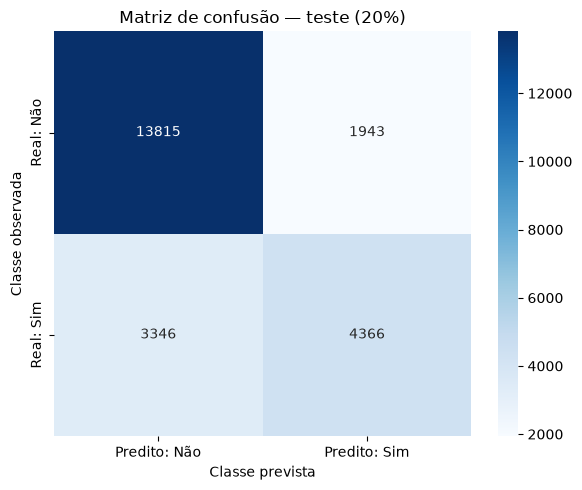

<Figure size 700x600 with 0 Axes>

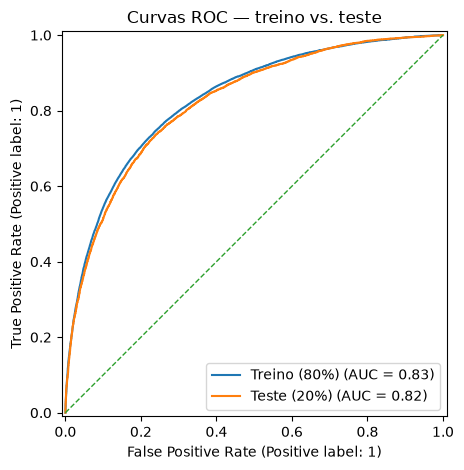

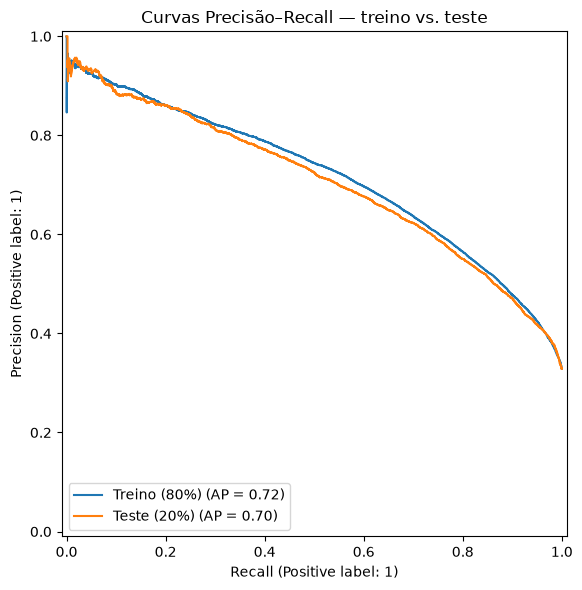

Average Precision — teste: 0.7044


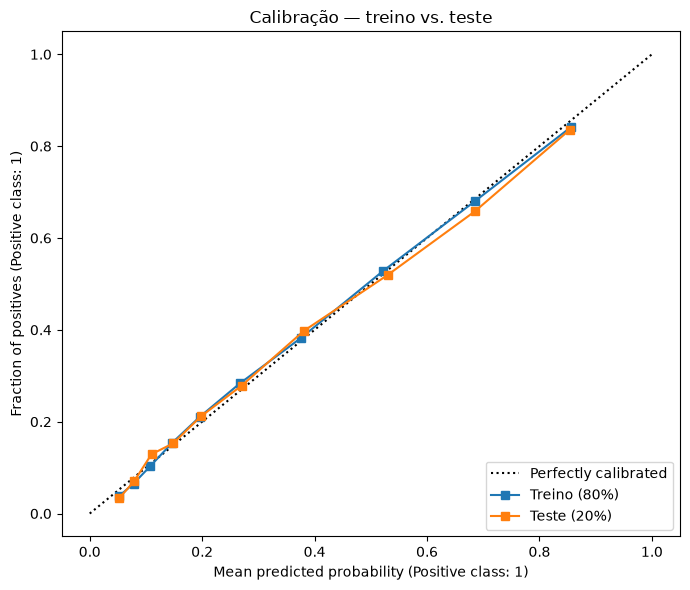

Brier score — treino: 0.1516
Brier score — teste:  0.1554
Brier score menor indica probabilidades mais próximas dos resultados observados, em média.


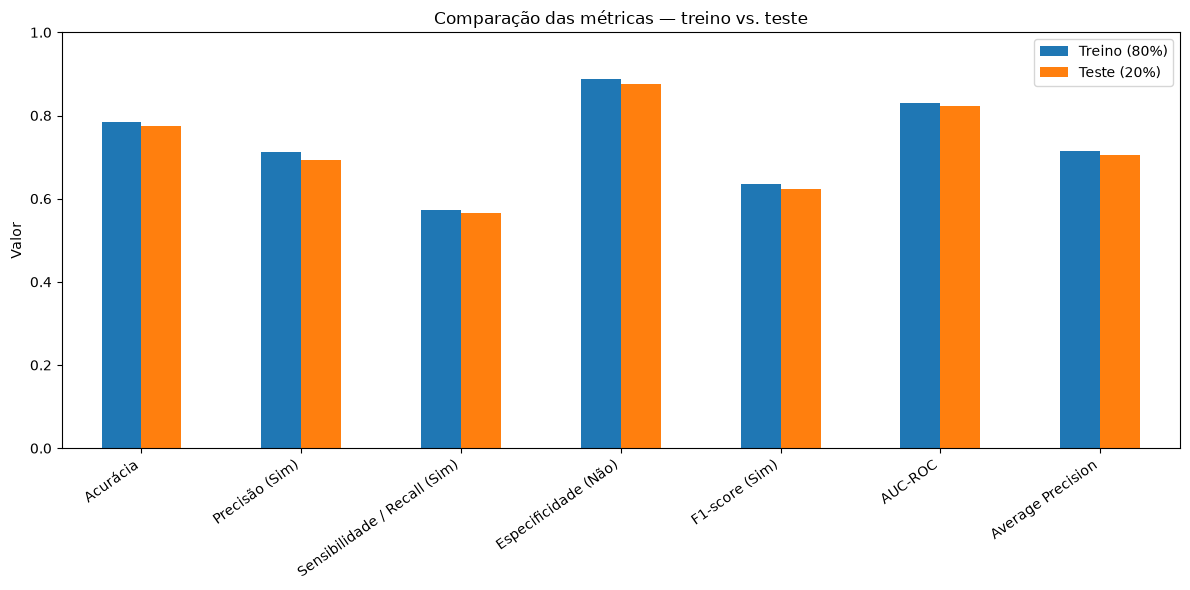


INTERPRETAÇÃO: diferenças grandes entre treino e teste podem indicar sobreajuste ou mudança de distribuição. A avaliação final deve considerar especialmente sensibilidade, precisão, AUC-ROC, Average Precision e calibração. O limiar padrão de 0,5 foi mantido; para aplicações sensíveis, ele deve ser escolhido com critérios explícitos usando dados de validação, não o teste final.


In [5]:
# ============================================================
# CÉLULA 2 — AVALIAÇÃO FINAL NO TESTE E COMPARAÇÃO COM TREINO
# ============================================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    RocCurveDisplay, PrecisionRecallDisplay, average_precision_score,
    brier_score_loss
)
from sklearn.calibration import CalibrationDisplay

# Predições no conjunto de teste (que não foi usado para ajustar o modelo)
y_test_pred = modelo.predict(X_test)
y_test_prob = modelo.predict_proba(X_test)[:, 1]

# Recalcular métricas comparáveis para treino e teste.
y_train_pred = modelo.predict(X_train)
y_train_prob = modelo.predict_proba(X_train)[:, 1]

def metricas_avaliacao(y_real, y_pred, y_prob):
    cm = confusion_matrix(y_real, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        "Acurácia": accuracy_score(y_real, y_pred),
        "Precisão (Sim)": precision_score(y_real, y_pred, zero_division=0),
        "Sensibilidade / Recall (Sim)": recall_score(y_real, y_pred, zero_division=0),
        "Especificidade (Não)": tn / (tn + fp) if (tn + fp) else np.nan,
        "Valor preditivo negativo": tn / (tn + fn) if (tn + fn) else np.nan,
        "F1-score (Sim)": f1_score(y_real, y_pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_real, y_prob) if pd.Series(y_real).nunique() == 2 else np.nan,
        "Average Precision": average_precision_score(y_real, y_prob),
        "Brier score (menor é melhor)": brier_score_loss(y_real, y_prob)
    }

m_treino = metricas_avaliacao(y_train, y_train_pred, y_train_prob)
m_teste = metricas_avaliacao(y_test, y_test_pred, y_test_prob)

comparacao = pd.DataFrame({
    f"Treino ({1-TEST_SIZE:.0%})": pd.Series(m_treino),
    f"Teste ({TEST_SIZE:.0%})": pd.Series(m_teste)
})
comparacao["Diferença (teste - treino)"] = comparacao[f"Teste ({TEST_SIZE:.0%})"] - comparacao[f"Treino ({1-TEST_SIZE:.0%})"]

print("COMPARAÇÃO DO DESEMPENHO: TREINO VS. TESTE")
display(comparacao.style.format("{:.4f}"))

print("\nRelatório de classificação — teste:")
print(classification_report(
    y_test, y_test_pred, labels=[0, 1],
    target_names=["Não (0)", "Sim (1)"], zero_division=0
))

# Intervalos de confiança de 95% por bootstrap no conjunto de teste.
# Bootstrap simples por linha; pressupõe observações independentes e não
# incorpora o desenho amostral complexo da PeNSE.
rng = np.random.default_rng(RANDOM_STATE)
B = 1000
metricas_boot = {
    "Acurácia": [],
    "Precisão (Sim)": [],
    "Sensibilidade / Recall (Sim)": [],
    "Especificidade (Não)": [],
    "F1-score (Sim)": [],
    "AUC-ROC": [],
    "Average Precision": []
}

yt = np.asarray(y_test)
yp = np.asarray(y_test_pred)
yb = np.asarray(y_test_prob)
n = len(yt)

for _ in range(B):
    idx = rng.integers(0, n, size=n)
    yt_b, yp_b, yb_b = yt[idx], yp[idx], yb[idx]
    cm_b = confusion_matrix(yt_b, yp_b, labels=[0, 1])
    tn, fp, fn, tp = cm_b.ravel()

    metricas_boot["Acurácia"].append(accuracy_score(yt_b, yp_b))
    metricas_boot["Precisão (Sim)"].append(precision_score(yt_b, yp_b, zero_division=0))
    metricas_boot["Sensibilidade / Recall (Sim)"].append(recall_score(yt_b, yp_b, zero_division=0))
    metricas_boot["Especificidade (Não)"].append(tn / (tn + fp) if (tn + fp) else np.nan)
    metricas_boot["F1-score (Sim)"].append(f1_score(yt_b, yp_b, zero_division=0))
    if np.unique(yt_b).size == 2:
        metricas_boot["AUC-ROC"].append(roc_auc_score(yt_b, yb_b))
        metricas_boot["Average Precision"].append(average_precision_score(yt_b, yb_b))
    else:
        metricas_boot["AUC-ROC"].append(np.nan)
        metricas_boot["Average Precision"].append(np.nan)

linhas_ci = []
for nome, valores in metricas_boot.items():
    valores = np.asarray(valores, dtype=float)
    valores = valores[np.isfinite(valores)]
    if len(valores):
        inferior, superior = np.percentile(valores, [2.5, 97.5])
        estimativa = m_teste[nome]
        linhas_ci.append({
            "Métrica": nome,
            "Estimativa no teste": estimativa,
            "IC 95% inferior": inferior,
            "IC 95% superior": superior
        })

ic_df = pd.DataFrame(linhas_ci)
print("\nINTERVALOS DE CONFIANÇA DE 95% — BOOTSTRAP NO TESTE")
display(ic_df.style.format({
    "Estimativa no teste": "{:.4f}",
    "IC 95% inferior": "{:.4f}",
    "IC 95% superior": "{:.4f}"
}))
print(
    "Nota: intervalos por bootstrap simples; não consideram pesos, estratos "
    "ou conglomerados do desenho amostral da PeNSE."
)

# Matriz de confusão — teste
cm_test = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predito: Não", "Predito: Sim"],
            yticklabels=["Real: Não", "Real: Sim"])
plt.title(f"Matriz de confusão — teste ({TEST_SIZE:.0%})")
plt.xlabel("Classe prevista")
plt.ylabel("Classe observada")
plt.tight_layout()
plt.show()

# Curvas ROC de treino e teste no mesmo gráfico
plt.figure(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_train, y_train_prob, name=f"Treino ({1-TEST_SIZE:.0%})")
RocCurveDisplay.from_predictions(y_test, y_test_prob, name=f"Teste ({TEST_SIZE:.0%})", ax=plt.gca())
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="Referência aleatória")
plt.title("Curvas ROC — treino vs. teste")
plt.tight_layout()
plt.show()

# Curvas Precisão–Recall de treino e teste
fig, ax = plt.subplots(figsize=(7, 6))
PrecisionRecallDisplay.from_predictions(y_train, y_train_prob, name=f"Treino ({1-TEST_SIZE:.0%})", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, y_test_prob, name=f"Teste ({TEST_SIZE:.0%})", ax=ax)
ax.set_title("Curvas Precisão–Recall — treino vs. teste")
plt.tight_layout()
plt.show()

print(f"Average Precision — teste: {average_precision_score(y_test, y_test_prob):.4f}")

# Curvas de calibração para comparar as probabilidades previstas
fig, ax = plt.subplots(figsize=(7, 6))
CalibrationDisplay.from_predictions(
    y_train, y_train_prob, n_bins=10, strategy="quantile",
    name=f"Treino ({1-TEST_SIZE:.0%})", ax=ax
)
CalibrationDisplay.from_predictions(
    y_test, y_test_prob, n_bins=10, strategy="quantile",
    name=f"Teste ({TEST_SIZE:.0%})", ax=ax
)
ax.set_title("Calibração — treino vs. teste")
plt.tight_layout()
plt.show()

print(f"Brier score — treino: {brier_score_loss(y_train, y_train_prob):.4f}")
print(f"Brier score — teste:  {brier_score_loss(y_test, y_test_prob):.4f}")
print("Brier score menor indica probabilidades mais próximas dos resultados observados, em média.")

# Comparação visual das principais métricas (excluindo Brier, em que menor é melhor)
metricas_plot = ["Acurácia", "Precisão (Sim)", "Sensibilidade / Recall (Sim)",
                 "Especificidade (Não)", "F1-score (Sim)", "AUC-ROC", "Average Precision"]
comparacao.loc[metricas_plot, [f"Treino ({1-TEST_SIZE:.0%})", f"Teste ({TEST_SIZE:.0%})"]].plot(
    kind="bar", figsize=(12, 6)
)
plt.title("Comparação das métricas — treino vs. teste")
plt.ylabel("Valor")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print(
    "\nINTERPRETAÇÃO: diferenças grandes entre treino e teste podem indicar "
    "sobreajuste ou mudança de distribuição. A avaliação final deve considerar "
    "especialmente sensibilidade, precisão, AUC-ROC, Average Precision e calibração. "
    "O limiar padrão de 0,5 foi mantido; para aplicações sensíveis, ele deve ser "
    "escolhido com critérios explícitos usando dados de validação, não o teste final."
)


In [6]:

# ============================================================
# CÉLULA 3 — 38 RESPOSTAS ALEATÓRIAS E PREVISÃO DO DESFECHO
# Não cria arquivos externos
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# ------------------------------------------------------------
# 1. CONFIGURAÇÃO
# ------------------------------------------------------------

# Usar exatamente as variáveis preditoras do modelo treinado.
colunas_perguntas = list(X.columns)

print(f"Número de preditores do modelo: {len(colunas_perguntas)}")

if len(colunas_perguntas) != 38:
    print(
        f"ATENÇÃO: o modelo utiliza {len(colunas_perguntas)} "
        "preditores, e não 38. Será respeitada a estrutura do modelo."
    )

# Gerador aleatório sem semente fixa: as respostas são sorteadas novamente
# a cada execução desta célula.
rng = np.random.default_rng()

# ------------------------------------------------------------
# 2. GERAR RESPOSTAS ALEATÓRIAS VÁLIDAS
# ------------------------------------------------------------

respostas = {}

for coluna in colunas_perguntas:

    # Selecionar aleatoriamente entre as categorias observadas
    # no conjunto de treinamento desta variável.
    valores_validos = (
        X_train[coluna]
        .dropna()
        .unique()
        .tolist()
    )

    if not valores_validos:
        raise ValueError(
            f"Não existem valores válidos para a variável: {coluna}"
        )

    respostas[coluna] = rng.choice(valores_validos)

# Criar uma linha com a mesma estrutura de X.
novo_estudante = pd.DataFrame(
    [respostas],
    columns=X.columns
).astype("object")

# ------------------------------------------------------------
# 3. PREVER A VARIÁVEL-CHAVE
# ------------------------------------------------------------

# Na Célula 1: 0 = Não (código original 1)
#               1 = Sim (código original 3)

probabilidades = modelo.predict_proba(novo_estudante)[0]
classes = list(modelo.classes_)

prob_nao = float(probabilidades[classes.index(0)])
prob_sim = float(probabilidades[classes.index(1)])

classe_prevista = int(modelo.predict(novo_estudante)[0])

rotulo_previsto = (
    "Sim — código original 3"
    if classe_prevista == 1
    else "Não — código original 1"
)

# ------------------------------------------------------------
# 4. MOSTRAR AS RESPOSTAS GERADAS
# ------------------------------------------------------------

tabela_respostas = pd.DataFrame({
    "Variável": colunas_perguntas,
    "Resposta aleatória gerada": [
        respostas[c] for c in colunas_perguntas
    ]
})

print("\n" + "=" * 65)
print("RESPOSTAS ALEATÓRIAS GERADAS")
print("=" * 65)

display(tabela_respostas)

# ------------------------------------------------------------
# 5. MOSTRAR A PREVISÃO
# ------------------------------------------------------------

resultado = pd.DataFrame({
    "Resultado": [
        "Probabilidade prevista — Não",
        "Probabilidade prevista — Sim",
        "Classe prevista pelo modelo"
    ],
    "Valor": [
        f"{prob_nao:.2%}",
        f"{prob_sim:.2%}",
        rotulo_previsto
    ]
})

print("\n" + "=" * 65)
print("PREVISÃO DA VARIÁVEL-CHAVE")
print("=" * 65)

display(resultado)

print(
    "\nNota: as respostas foram geradas aleatoriamente a partir "
    "das categorias observadas no treino. Essa combinação pode "
    "não corresponder a um estudante real. A previsão é apenas "
    "uma demonstração do funcionamento do modelo."
)


Número de preditores do modelo: 38

RESPOSTAS ALEATÓRIAS GERADAS


,Variável,Resposta aleatória gerada
0,CAPITAL - indica se é município da capital,0
1,B01001A - Qual é o seu sexo?,2
2,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",2
3,B01002 - Qual é a sua cor ou raça?,0
4,B01006 - Você mora com sua mãe?,3
5,B01007 - Você mora com seu pai?,1
6,B01015B - Na sua casa tem computador ou notebook?,1
7,B01016 - Você tem acesso à internet em sua casa?,3
8,"B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as au...",3
9,B03010C - Quantas horas por dia você costuma f...,3



PREVISÃO DA VARIÁVEL-CHAVE


,Resultado,Valor
0,Probabilidade prevista — Não,23.16%
1,Probabilidade prevista — Sim,76.84%
2,Classe prevista pelo modelo,Sim — código original 3



Nota: as respostas foram geradas aleatoriamente a partir das categorias observadas no treino. Essa combinação pode não corresponder a um estudante real. A previsão é apenas uma demonstração do funcionamento do modelo.


In [8]:

# ============================================================
# PENSE 2024 — REGRESSÃO LOGÍSTICA PARA ANÁLISE DE ASSOCIAÇÕES
# Desfecho: B12009
# Resultado: OR ajustado, IC 95%, valor-p e valor-p ajustado
# ============================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. CARREGAR A BASE ORIGINAL
# ------------------------------------------------------------

arquivo = Path(
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "07_PENSE2024_IDADE_13_A_17_CATEGORY.feather"
)

df = pd.read_feather(arquivo)

target = (
    "B12009 - NOS ÚLTIMOS 12 MESES, "
    "alguma vez você sentiu vontade de se machucar de propósito?"
)

if target not in df.columns:
    raise ValueError(f"Coluna não encontrada: {target}")

print("Dimensões originais:", df.shape)
print("\nDistribuição de B12009:")
print(df[target].value_counts(dropna=False))

# ------------------------------------------------------------
# 2. DEFINIR O DESFECHO BINÁRIO
# 1 original = Não; 3 original = Sim
# Código 0 e outras respostas são excluídos
# ------------------------------------------------------------

codigo = pd.to_numeric(df[target], errors="coerce")
validos = codigo.isin([1, 3])

dados = df.loc[validos].copy()
dados["B12009_bin"] = codigo.loc[validos].map(
    {1: 0, 3: 1}
).astype(int)

print("\nRegistros analisados:", len(dados))
print("\nProporção das respostas:")
print(
    dados["B12009_bin"]
    .map({0: "Não", 1: "Sim"})
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# ------------------------------------------------------------
# 3. PREPARAR AS VARIÁVEIS PREDITORAS
# ------------------------------------------------------------

# Excluir o desfecho e eventuais identificadores.
# Acrescente aqui identificadores ou variáveis administrativas
# que não devam entrar no modelo, se existirem na sua base.

colunas_excluir = [
    target,
    "B12009_bin",
    # "ID_ALUNO",
    # "ID_ESCOLA",
]

preditores = [
    c for c in dados.columns
    if c not in colunas_excluir
]

# Tratar cada preditor como categórico.
for c in preditores:
    dados[c] = (
        dados[c]
        .astype("string")
        .fillna("Não informado")
        .replace(r"^\s*$", "Não informado", regex=True)
        .astype(str)
    )

# Remover variáveis constantes.
preditores = [
    c for c in preditores
    if dados[c].nunique(dropna=False) > 1
]

print("\nNúmero de perguntas preditoras:", len(preditores))

# ------------------------------------------------------------
# 4. AJUSTAR A REGRESSÃO LOGÍSTICA
# ------------------------------------------------------------

# C(Q(...)) informa ao modelo que cada variável é categórica.
# A categoria de referência é definida pela codificação do Patsy.

termos = [f"C(Q({c!r}))" for c in preditores]
formula = "B12009_bin ~ " + " + ".join(termos)

print("\nAjustando o modelo...")
print("O modelo inclui todas as variáveis preditoras acima.")

modelo_assoc = smf.glm(
    formula=formula,
    data=dados,
    family=sm.families.Binomial()
).fit(maxiter=100)

print("\nConvergiu:", modelo_assoc.converged)
print("Observações:", int(modelo_assoc.nobs))

# ------------------------------------------------------------
# 5. EXTRAIR ODDS RATIOS, IC 95% E VALORES-P
# ------------------------------------------------------------

ic = modelo_assoc.conf_int()

resultados = pd.DataFrame({
    "Termo": modelo_assoc.params.index,
    "Coeficiente": modelo_assoc.params.values,
    "Erro_padrao": modelo_assoc.bse.values,
    "OR_ajustado": np.exp(modelo_assoc.params.values),
    "IC95_inferior": np.exp(ic.iloc[:, 0].values),
    "IC95_superior": np.exp(ic.iloc[:, 1].values),
    "Valor_p": modelo_assoc.pvalues.values,
})

# Excluir o intercepto da tabela de categorias.
resultados = resultados[
    resultados["Termo"] != "Intercept"
].copy()

# Identificar a pergunta original de cada categoria.
def identificar_variavel(termo):
    for c in preditores:
        prefixo = f"C(Q({c!r}))"
        if termo.startswith(prefixo + "["):
            return c
    return "Verificar termo"

resultados["Pergunta_original"] = (
    resultados["Termo"].map(identificar_variavel)
)

# ------------------------------------------------------------
# 6. CORREÇÃO PARA MÚLTIPLAS COMPARAÇÕES
# Benjamini-Hochberg: controla a taxa esperada de falsas
# descobertas entre os contrastes testados.
# ------------------------------------------------------------

resultados["Valor_p_BH"] = multipletests(
    resultados["Valor_p"],
    method="fdr_bh"
)[1]

resultados["IC95_exclui_1"] = (
    (resultados["IC95_inferior"] > 1) |
    (resultados["IC95_superior"] < 1)
)

resultados["Associacao_p05"] = resultados["Valor_p"] < 0.05
resultados["Associacao_BH05"] = resultados["Valor_p_BH"] < 0.05

# Ordenar por evidência estatística ajustada.
resultados = resultados.sort_values(
    "Valor_p_BH",
    ascending=True
)

colunas_saida = [
    "Pergunta_original",
    "Termo",
    "OR_ajustado",
    "IC95_inferior",
    "IC95_superior",
    "Valor_p",
    "Valor_p_BH",
    "IC95_exclui_1",
    "Associacao_BH05",
]

print("\nRESULTADOS — PRIMEIRAS 40 CATEGORIAS")
display(
    resultados[colunas_saida]
    .head(40)
    .round(4)
)

# ------------------------------------------------------------
# 7. RESUMO POR PERGUNTA ORIGINAL
# ------------------------------------------------------------

resumo = (
    resultados.groupby("Pergunta_original")
    .agg(
        Numero_de_categorias=("Termo", "count"),
        Categorias_significativas_BH=(
            "Associacao_BH05", "sum"
        ),
        Menor_valor_p_BH=("Valor_p_BH", "min"),
    )
    .sort_values("Menor_valor_p_BH")
)

print("\nRESUMO POR PERGUNTA ORIGINAL")
display(resumo.round(4))

# ------------------------------------------------------------
# 8. VERIFICAR OS RESULTADOS
# ------------------------------------------------------------

print("\nNúmero total de contrastes categóricos:",
      len(resultados))

print("Contrastes com valor-p < 0,05:",
      int(resultados["Associacao_p05"].sum()))

print("Contrastes com valor-p ajustado BH < 0,05:",
      int(resultados["Associacao_BH05"].sum()))

print(
    "\nATENÇÃO: os resultados são associações ajustadas. "
    "Não demonstram causalidade. Os intervalos e valores-p "
    "acima são convencionais e ainda não incorporam o "
    "desenho amostral complexo da PeNSE."
)


Dimensões originais: (118036, 39)

Distribuição de B12009:
B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você sentiu vontade de se machucar de propósito?
1    78786
3    38561
0      689
Name: count, dtype: int64

Registros analisados: 117347

Proporção das respostas:
B12009_bin
Não    67.14
Sim    32.86
Name: proportion, dtype: float64

Número de perguntas preditoras: 38

Ajustando o modelo...
O modelo inclui todas as variáveis preditoras acima.

Convergiu: True
Observações: 117347

RESULTADOS — PRIMEIRAS 40 CATEGORIAS


/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/.venv/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


,Pergunta_original,Termo,OR_ajustado,IC95_inferior,IC95_superior,Valor_p,Valor_p_BH,IC95_exclui_1,Associacao_BH05
2,B01001A - Qual é o seu sexo?,C(Q('B01001A - Qual é o seu sexo?'))[T.2],1.5886,1.5361,1.6429,0.0000,0.0000,True,True
3,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS","C(Q('IDADE_AGREG - IDADE DO ESTUDANTE, CATEGOR...",0.8199,0.7936,0.8469,0.0000,0.0000,True,True
63,"B12008 - NOS ÚLTIMOS 30 DIAS, com que frequênc...","C(Q('B12008 - NOS ÚLTIMOS 30 DIAS, com que fre...",3.1274,2.2194,4.4069,0.0000,0.0000,True,True
20,B03010C - Quantas horas por dia você costuma f...,C(Q('B03010C - Quantas horas por dia você cost...,1.1523,1.0956,1.2120,0.0000,0.0000,True,True
62,"B12008 - NOS ÚLTIMOS 30 DIAS, com que frequênc...","C(Q('B12008 - NOS ÚLTIMOS 30 DIAS, com que fre...",1.9842,1.4083,2.7955,0.0001,0.0016,True,True
71,"B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes...","C(Q('B09010A1 - NOS ÚLTIMOS 12 MESES, quantas ...",1.8050,1.3294,2.4508,0.0002,0.0022,True,True
75,"B09016A2 - Alguma vez na vida alguém ameaçou, ...",C(Q('B09016A2 - Alguma vez na vida alguém amea...,1.6010,1.2309,2.0825,0.0005,0.0056,True,True
54,"B12005 - NOS ÚLTIMOS 30 DIAS, com que frequênc...","C(Q('B12005 - NOS ÚLTIMOS 30 DIAS, com que fre...",2.2196,1.3908,3.5425,0.0008,0.0090,True,True
72,B09016A1 - Alguma vez na vida alguém o(a) toco...,C(Q('B09016A1 - Alguma vez na vida alguém o(a)...,0.6394,0.4840,0.8447,0.0016,0.0159,True,True
1,CAPITAL - indica se é município da capital,C(Q('CAPITAL - indica se é município da capita...,1.0468,1.0159,1.0787,0.0028,0.0243,True,True



RESUMO POR PERGUNTA ORIGINAL


,Numero_de_categorias,Categorias_significativas_BH,Menor_valor_p_BH
Pergunta_original,,,
B01001A - Qual é o seu sexo?,1,1,0.0000
"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",1,1,0.0000
"B12008 - NOS ÚLTIMOS 30 DIAS, com que frequência você sentiu que a vida não vale a pena ser vivida?",3,2,0.0000
"B03010C - Quantas horas por dia você costuma ficar sentado(a), assistindo televisão, jogando videogame, usando computador, celular, tablet ou fazendo outras atividades sentado(a)? (NÃO contar sábado, domingo, feriados ou o tempo sentado na escola)",2,1,0.0000
"B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?",2,1,0.0022
"B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?",2,1,0.0056
"B12005 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu triste?",3,1,0.0090
"B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?",2,1,0.0159
CAPITAL - indica se é município da capital,1,1,0.0243



Número total de contrastes categóricos: 87
Contrastes com valor-p < 0,05: 24
Contrastes com valor-p ajustado BH < 0,05: 16

ATENÇÃO: os resultados são associações ajustadas. Não demonstram causalidade. Os intervalos e valores-p acima são convencionais e ainda não incorporam o desenho amostral complexo da PeNSE.
